In [33]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [34]:
'''
X_train = np.load("X_train.npy")
X_test = np.load("X_test.npy")

y_train_clf = np.load("y_train_clf.npy")
y_test_clf = np.load("y_test_clf.npy")

y_train_reg = np.load("y_train_reg.npy")
y_test_reg = np.load("y_test_reg.npy")
'''

'\nX_train = np.load("X_train.npy")\nX_test = np.load("X_test.npy")\n\ny_train_clf = np.load("y_train_clf.npy")\ny_test_clf = np.load("y_test_clf.npy")\n\ny_train_reg = np.load("y_train_reg.npy")\ny_test_reg = np.load("y_test_reg.npy")\n'

### Load your preprocessed training data

In [35]:
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train_clf = pd.read_csv("y_train_clf.csv")
y_test_clf = pd.read_csv("y_test_clf.csv")
y_train_reg = pd.read_csv("y_train_reg.csv")
y_test_reg = pd.read_csv("y_test_reg.csv")

In [36]:
X_train.head()

,Square_Footage,Lot_Size_Acres,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age,Transit_to_Distance_Ratio,...,Property_Type_Townhouse,Zoning_Code_COMM,Zoning_Code_MIXED,Zoning_Code_RES-A,Zoning_Code_RES-B,Country_Code_DE,Country_Code_FR,Country_Code_IN,Country_Code_UK,Country_Code_US
0,-1.174258,-0.691411,0.500187,-0.063736,-0.788481,5,0.604643,0.0,0.978674,-0.523660,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,1.622780,-1.569816,0.252736,0.240586,0.386434,1,1.367528,5.0,1.610624,-0.449545,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.708037,-0.326077,0.872535,-0.983808,-0.291402,5,0.882056,0.0,-1.416085,-0.623923,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
3,-1.485095,1.610348,0.954521,-0.867098,1.019080,8,0.361907,3.0,-1.283043,-0.621790,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-0.412931,-0.173449,-1.092221,0.962818,-0.924048,9,-0.678390,3.0,1.377800,0.619132,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


### Calculate the Pearson correlation matrix for all features against the regression target (Sale_Price)

In [37]:
train_df = X_train.copy()
train_df["target"] = y_train_reg

# Pearson correlation of every feature with target
correlation = (train_df.corr(numeric_only=True)["target"].drop("target").sort_values(ascending=False))
print(correlation)

Square_Footage                 0.895718
Property_Type_Commercial       0.300000
Zoning_Code_COMM               0.300000
Energy_Efficiency_Rating       0.066901
School_District_Rating         0.038983
Transit_Score                  0.016019
Transit_to_Distance_Ratio      0.010904
Country_Code_DE                0.001496
Country_Code_UK                0.000876
Property_Age                   0.000317
Country_Code_IN                0.000274
Lot_Size_Acres                 0.000062
Environmental_Risk_Score      -0.001076
Country_Code_US               -0.001181
Country_Code_FR               -0.001347
Crime_Index                   -0.009584
Distance_To_City_Center_KM    -0.016418
Property_Type_Multi-Family    -0.026998
Property_Type_Townhouse       -0.054003
Property_Type_Condo           -0.073609
Zoning_Code_RES-A             -0.077855
Zoning_Code_RES-B             -0.079688
Zoning_Code_MIXED             -0.080690
Property_Type_Single Family   -0.102684
Name: target, dtype: float64


### Plot a Seaborn heatmap of the top 10 most highly correlated features. Save as reg_correlation.png.

In [38]:
train_df = X_train.copy()
train_df["target"] = y_train_reg.squeeze()

# Calculate correlation with target
correlation = (train_df.corr(numeric_only=True)["target"].drop("target"))

# Select top 10 features by absolute correlation
top_10_features = correlation.abs().nlargest(10).index

# Create correlation matrix for top 10 features + target
top_corr_matrix = train_df[list(top_10_features) + ["target"]].corr()

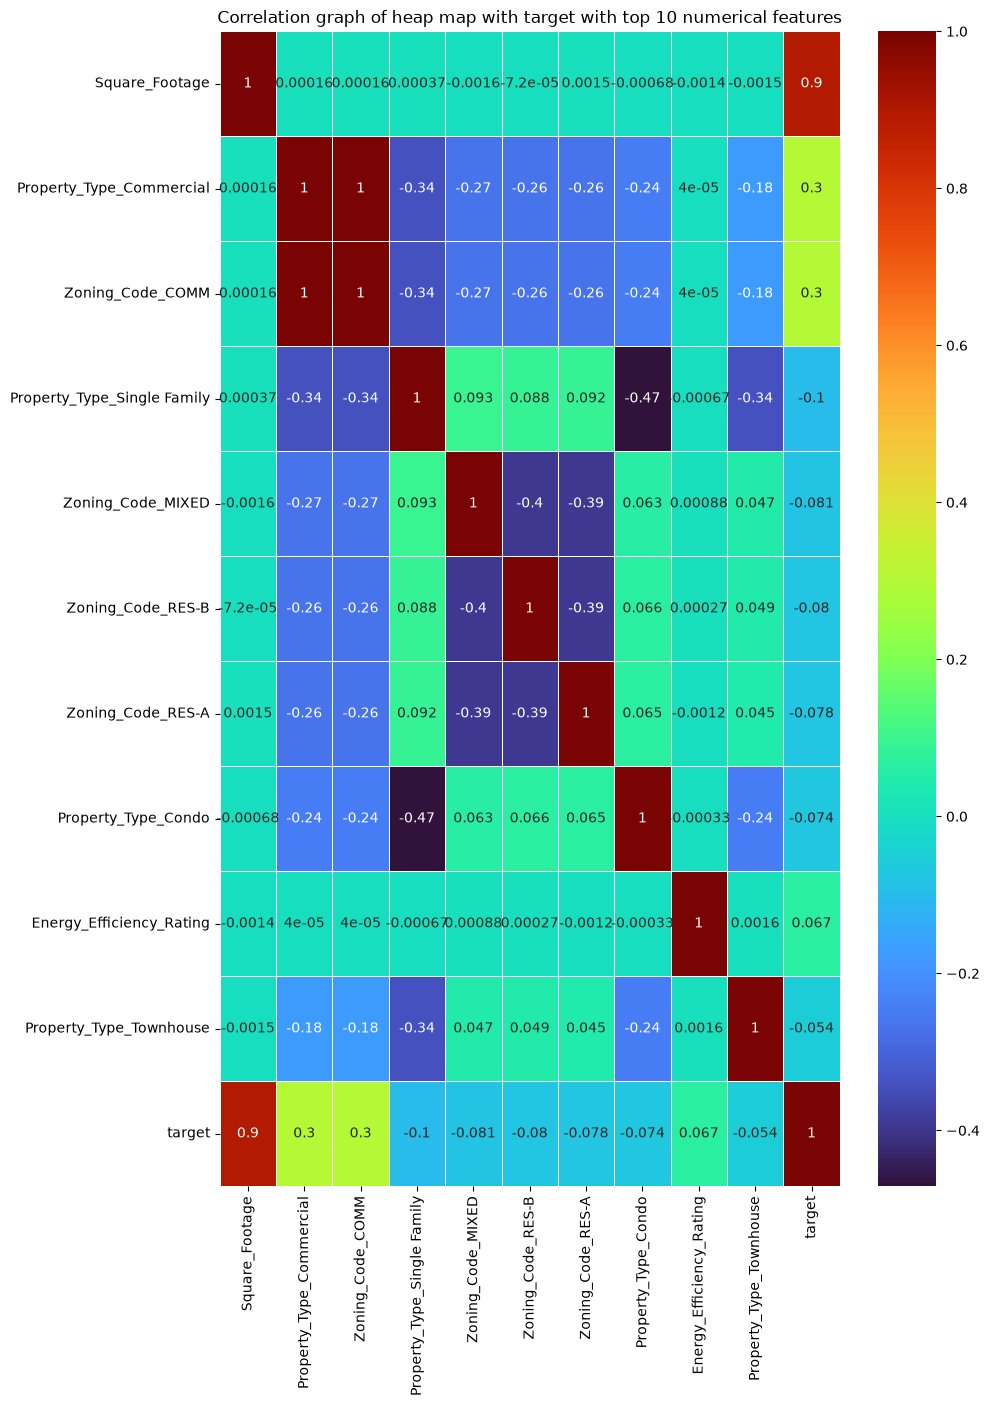

In [39]:
plt.figure(figsize= (10, 15 ))
sns.heatmap(top_corr_matrix, annot = True, cmap= 'turbo', fmt=".2g",linewidths=0.5)
plt.title("Correlation graph of heap map with target with top 10 numerical features")
plt.savefig('reg_correlation.png', dpi = 300, bbox_inches='tight')
plt.show()

In [40]:
y_train_clf

,Is_High_Risk
0,0
1,0
2,0
3,0
4,0
...,...
799995,0
799996,0
799997,0
799998,0


### Calculate the Point-Biserial correlation for all features against the classification target (Is_High_Risk)

In [41]:
from scipy.stats import pointbiserialr

# Make sure y_train should be 1 D array.
y = y_train_clf.squeeze()

In [42]:
results = {}

# Calculate point-biserial correlation for every numeric feature
for column in X_train.select_dtypes(include="number").columns:
    r, p_value = pointbiserialr(X_train[column], y)
    results[column] = {
        "point_biserial_correlation": r,
        "p_value": p_value
    }

In [43]:
# Convert to DataFrame
point_biserial_df = pd.DataFrame(results).T

# Sort by absolute correlation
point_biserial_df = point_biserial_df.loc[point_biserial_df["point_biserial_correlation"].abs().sort_values(ascending=False).index]
print(point_biserial_df)

                             point_biserial_correlation        p_value
Environmental_Risk_Score                       0.246062   0.000000e+00
Crime_Index                                    0.223101   0.000000e+00
Property_Age                                   0.109041   0.000000e+00
Transit_Score                                 -0.076410   0.000000e+00
Distance_To_City_Center_KM                     0.074887   0.000000e+00
Transit_to_Distance_Ratio                     -0.039153  7.081124e-269
Square_Footage                                -0.003687   9.755346e-04
Country_Code_IN                                0.002216   4.742864e-02
Lot_Size_Acres                                 0.001974   7.749827e-02
Property_Type_Commercial                      -0.001166   2.969607e-01
Zoning_Code_COMM                              -0.001166   2.969607e-01
Country_Code_DE                               -0.001010   3.663394e-01
Country_Code_US                               -0.000995   3.734492e-01
Countr

### Identify multicollinearity: Calculate the Variance Inflation Factor (VIF) for your numerical features.

In [44]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numerical features
X_numeric = X_train.select_dtypes(include="number").copy()

In [45]:
# Calculate VIF
vif_df = pd.DataFrame()

vif_df["Feature"] = X_numeric.columns
vif_df["VIF"] = [variance_inflation_factor(X_numeric.values, i) for i in range(X_numeric.shape[1])]

C:\Users\ravis\anaconda3\envs\nexlyra\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [46]:
# Sort highest VIF first
vif_df = vif_df.sort_values("VIF", ascending=False)
print(vif_df)

                        Feature        VIF
16            Zoning_Code_MIXED        inf
17            Zoning_Code_RES-A        inf
15             Zoning_Code_COMM        inf
14      Property_Type_Townhouse        inf
12   Property_Type_Multi-Family        inf
13  Property_Type_Single Family        inf
10     Property_Type_Commercial        inf
11          Property_Type_Condo        inf
20              Country_Code_FR        inf
21              Country_Code_IN        inf
18            Zoning_Code_RES-B        inf
19              Country_Code_DE        inf
22              Country_Code_UK        inf
23              Country_Code_US        inf
2    Distance_To_City_Center_KM  13.848519
3                 Transit_Score   7.430387
9     Transit_to_Distance_Ratio   3.990770
0                Square_Footage   1.000031
6      Environmental_Risk_Score   1.000024
8                  Property_Age   1.000020
7      Energy_Efficiency_Rating   1.000017
1                Lot_Size_Acres   1.000017
5        Sc

In [47]:
X_train.shape

(800000, 24)

### Drop any features with a VIF > 10 to prevent model instability.

In [48]:
## I am selecting the features manually because many of them showing inf because of onehot encoding and value more than 10.

selected = ['Zoning_Code_MIXED','Property_Type_Townhouse','Country_Code_FR','Distance_To_City_Center_KM']
X_train_df = X_train.drop(columns=selected)
X_test_df = X_test.drop(columns=selected)

In [49]:
X_train_df.shape

(800000, 20)

In [54]:
### after dropping the selected columns
X_numeric_2 = X_train_df.select_dtypes(include="number").copy()
vif = pd.DataFrame()

vif["Feature"] = X_numeric_2.columns
vif["VIF"] = [variance_inflation_factor(X_numeric_2.values, i) for i in range(X_numeric_2.shape[1])]

vif = vif.sort_values("VIF", ascending=False)
print(vif)

C:\Users\ravis\anaconda3\envs\nexlyra\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


                        Feature       VIF
13             Zoning_Code_COMM       inf
9      Property_Type_Commercial       inf
4        School_District_Rating  3.942496
19              Country_Code_US  3.331805
12  Property_Type_Single Family  2.925932
6      Energy_Efficiency_Rating  2.858200
10          Property_Type_Condo  2.206090
18              Country_Code_UK  2.170969
17              Country_Code_IN  1.878582
16              Country_Code_DE  1.872320
15            Zoning_Code_RES-B  1.850675
14            Zoning_Code_RES-A  1.848874
8     Transit_to_Distance_Ratio  1.525968
2                 Transit_Score  1.525954
11   Property_Type_Multi-Family  1.241876
0                Square_Footage  1.000027
5      Environmental_Risk_Score  1.000019
7                  Property_Age  1.000017
1                Lot_Size_Acres  1.000013
3                   Crime_Index  1.000013


In [53]:
X_train_df.shape

(800000, 20)

In [56]:
vif.columns

Index(['Feature', 'VIF'], dtype='str')

In [58]:
((vif['Feature'] == "Zoning_Code_COMM").values == (vif['Feature']=="Property_Type_Commercial").values).all()

np.False_

In [68]:
print((X_train_df.shape, y_train_reg.shape))

((800000, 20), (800000, 1))


### Perform Mutual Information (mutual_info_regression) scoring to rank feature importance for Sale_Price.

In [69]:
from sklearn.feature_selection import mutual_info_regression

In [70]:
y = y_train_reg.squeeze()
mi_scores = mutual_info_regression(X_train_df,y,random_state=42)

mi_df = pd.DataFrame({
    "Feature": X_train_df.columns,
    "MI_Score": mi_scores}).sort_values("MI_Score",ascending=False).reset_index(drop=True)

print(mi_df)

                        Feature  MI_Score
0                Square_Footage  1.317532
1      Property_Type_Commercial  0.080668
2              Zoning_Code_COMM  0.080668
3   Property_Type_Single Family  0.019051
4             Zoning_Code_RES-A  0.011200
5           Property_Type_Condo  0.010843
6             Zoning_Code_RES-B  0.010645
7      Energy_Efficiency_Rating  0.007645
8        School_District_Rating  0.004092
9                 Transit_Score  0.002282
10   Property_Type_Multi-Family  0.002041
11    Transit_to_Distance_Ratio  0.000918
12               Lot_Size_Acres  0.000876
13              Country_Code_DE  0.000811
14                  Crime_Index  0.000446
15                 Property_Age  0.000083
16     Environmental_Risk_Score  0.000000
17              Country_Code_IN  0.000000
18              Country_Code_UK  0.000000
19              Country_Code_US  0.000000


In [71]:
###  Perform Mutual Information (mutual_info_classif) scoring to rank feature importance for Is_High_Risk.

In [72]:
from sklearn.feature_selection import mutual_info_classif

In [73]:
y_clf = y_train_clf.squeeze()
mi_scores = mutual_info_classif(X_train_df,y_clf,random_state=42)

In [74]:
mi_df = pd.DataFrame({
    "Feature": X_train_df.columns,
    "MI_Score": mi_scores})

In [75]:
mi_df = mi_df.sort_values(by="MI_Score", ascending=False).reset_index(drop=True)
print(mi_df)

                        Feature  MI_Score
0   Property_Type_Single Family  0.076345
1               Country_Code_US  0.076100
2      Environmental_Risk_Score  0.045083
3             Zoning_Code_RES-B  0.040183
4             Zoning_Code_RES-A  0.039308
5                   Crime_Index  0.034848
6           Property_Type_Condo  0.031628
7      Energy_Efficiency_Rating  0.030654
8               Country_Code_UK  0.020151
9        School_District_Rating  0.016843
10     Property_Type_Commercial  0.011490
11             Zoning_Code_COMM  0.011418
12              Country_Code_DE  0.011338
13              Country_Code_IN  0.010864
14                 Property_Age  0.007624
15                Transit_Score  0.007458
16    Transit_to_Distance_Ratio  0.003353
17   Property_Type_Multi-Family  0.002527
18               Lot_Size_Acres  0.000232
19               Square_Footage  0.000137


###  to generate the code for Principal Component Analysis (PCA). Apply PCA to reduce the dimensionality of your One-Hot Encoded country/zoning variables.

In [81]:
from sklearn.decomposition import PCA

In [82]:
country_columns = [col for col in X_train.columns if col.startswith("Country_Code_")]
zoning_columns = [col for col in X_train.columns if col.startswith("Zoning_Code_")]

In [83]:
pca_columns = country_columns + zoning_columns
print("Number of OHE columns:", len(pca_columns))

Number of OHE columns: 9


### Keep enough PCA components to explain 90% of the variance.

In [84]:
pca = PCA(n_components=0.90,random_state=42)

In [85]:
X_train_pca = pca.fit_transform(X_train[pca_columns])
X_test_pca = pca.transform(X_test[pca_columns])

In [88]:
print(f"Original features: {len(pca_columns)}")
print(f"PCA components : {pca.n_components_ }")
print(f"Explained variance: {pca.explained_variance_ratio_.sum()}")

Original features: 9
PCA components : 6
Explained variance: 0.9265261970847374


### Plot the cumulative explained variance ratio of your PCA components. Save as pca_variance.png.

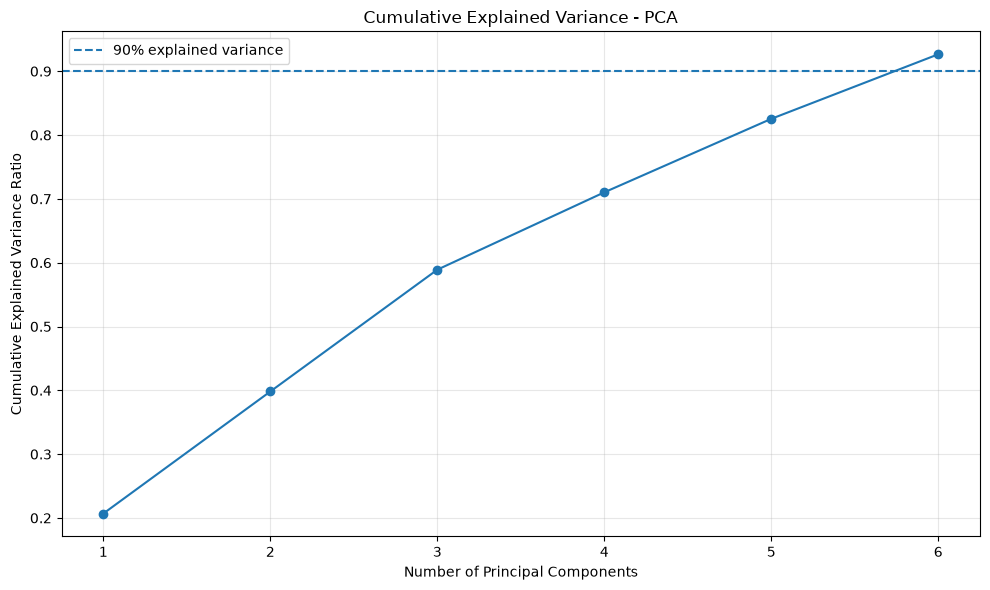

In [89]:
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)


plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1),cumulative_variance,marker="o")
plt.axhline(y=0.90,linestyle="--",label="90% explained variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.title("Cumulative Explained Variance - PCA")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("pca_variance.png",dpi=300,bbox_inches="tight")
plt.show()

###  Analyze the class imbalance of 'Is_High_Risk'. Calculate the exact ratio of 0s to 1s

In [91]:
y_train_clf.value_counts()

Is_High_Risk
0               776694
1                23306
Name: count, dtype: int64

In [92]:
# Count 0s and 1s
class_counts = y_train_clf.value_counts().sort_index()

count_0 = class_counts.get(0, 0)
count_1 = class_counts.get(1, 0)

# Exact ratio: 0s : 1s
ratio_0_to_1 = count_0 / count_1

print("Number of 0s:", count_0)
print("Number of 1s:", count_1)
print("Ratio (0 : 1):", f"{count_0}:{count_1}")
print("Exact ratio (0 / 1):", ratio_0_to_1)

Number of 0s: 776694
Number of 1s: 23306
Ratio (0 : 1): 776694:23306
Exact ratio (0 / 1): 33.32592465459538


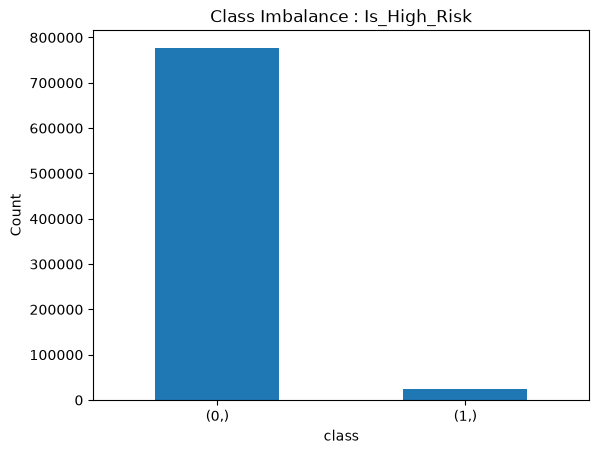

In [100]:
y_train_clf.value_counts().plot(kind='bar')
plt.title('Class Imbalance : Is_High_Risk')
plt.xlabel('class')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

###  Apply SMOTE (Synthetic Minority Over-sampling Technique) from `imblearn` to balance the training data for the classification task.

In [95]:
from imblearn.over_sampling import SMOTE

In [96]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_clf_smote = smote.fit_resample(X_train_df,y_train_clf.squeeze())

### Verify the new shape of the SMOTE-resampled training data.

In [115]:
print(f"Before SMOTE:{y_train_clf.value_counts()}")
print(f"After SMOTE:{y_train_clf_smote.value_counts()}")

print(f"Original shape:{X_train.shape}")
print(f"SMOTE shape:{X_train_smote.shape}")


Before SMOTE:Is_High_Risk
0               776694
1                23306
Name: count, dtype: int64
After SMOTE:Is_High_Risk
0    776694
1    776694
Name: count, dtype: int64
Original shape:(800000, 24)
SMOTE shape:(1553388, 20)


### Plot a bar chart showing the class distribution before and after SMOTE. Save as smote_balance.png.

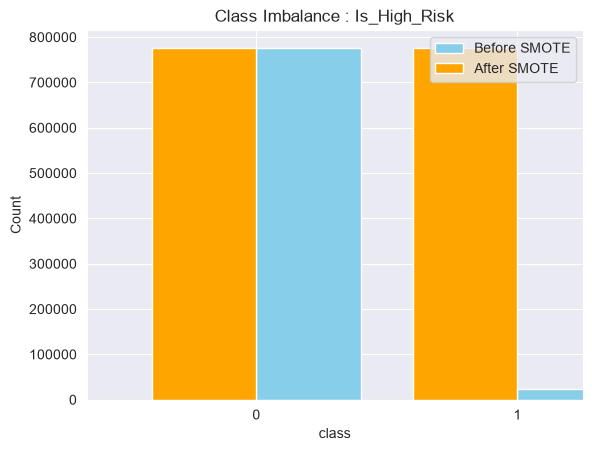

In [107]:
sns.set_style('darkgrid')
y_train_clf.value_counts().sort_index().plot(kind='bar', color='skyblue', width=0.4, position=0, label='Before SMOTE')
y_train_clf_smote.value_counts().sort_index().plot( kind='bar', color='orange', width=0.4, position=1, label='After SMOTE')
plt.title('Class Imbalance : Is_High_Risk')
plt.xlabel('class')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend()
plt.savefig("smote_balance.png",dpi=300,bbox_inches="tight")
plt.show()

### 17. Perform a baseline DummyRegressor (strategy='mean') to establish a baseline RMSE for Sale_Price.

In [108]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error

In [109]:
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train_df, y_train_reg)

,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'mean'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None
Name,Type,Value
"constant_ constant_: ndarray of shape (1, n_outputs)Mean or median or quantile of the training targets or constant valuegiven by the user.","ndarray[float64](1, 1)",[[2235944.59]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](20,)","['Square_Footage','Lot_Size_Acres','Transit_Score',...,'Country_Code_IN', 'Country_Code_UK','Country_Code_US']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,20
n_outputs_ n_outputs_: intNumber of outputs.,int,1


In [110]:
y_pred_dummy = dummy.predict(X_test_df)

In [111]:
rmse_dummy = np.sqrt(mean_squared_error(y_test_reg, y_pred_dummy))
print("Baseline DummyRegressor RMSE:", rmse_dummy)

Baseline DummyRegressor RMSE: 1240631.2978392674


### Perform a baseline DummyClassifier (strategy='prior') to establish a baseline ROC-AUC for Is_High_Risk.

In [113]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score

dummy = DummyClassifier(strategy='prior', random_state=42)
dummy.fit(X_train_smote, y_train_clf_smote)

y_prob_dummy = dummy.predict_proba(X_test_df)[:, 1]
roc_auc_dummy = roc_auc_score(y_test_clf,y_prob_dummy)
print(f"Baseline DummyClassifier ROC-AUC: {roc_auc_dummy:.4f}")

Baseline DummyClassifier ROC-AUC: 0.5000


###  review your feature selection logic and suggest one additional domain-specific feature interaction.


In [114]:
X_train_smote.head()

,Square_Footage,Lot_Size_Acres,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age,Transit_to_Distance_Ratio,Property_Type_Commercial,Property_Type_Condo,Property_Type_Multi-Family,Property_Type_Single Family,Zoning_Code_COMM,Zoning_Code_RES-A,Zoning_Code_RES-B,Country_Code_DE,Country_Code_IN,Country_Code_UK,Country_Code_US
0,-1.174258,-0.691411,-0.063736,-0.788481,5,0.604643,0.0,0.978674,-0.523660,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
1,1.622780,-1.569816,0.240586,0.386434,1,1.367528,5.0,1.610624,-0.449545,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.708037,-0.326077,-0.983808,-0.291402,5,0.882056,0.0,-1.416085,-0.623923,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,-1.485095,1.610348,-0.867098,1.019080,8,0.361907,3.0,-1.283043,-0.621790,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,-0.412931,-0.173449,0.962818,-0.924048,9,-0.678390,3.0,1.377800,0.619132,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [116]:
X_train = X_train.copy()
y_train_reg = y_train_reg.copy()

In [117]:
X_train.head()

,Square_Footage,Lot_Size_Acres,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age,Transit_to_Distance_Ratio,...,Property_Type_Townhouse,Zoning_Code_COMM,Zoning_Code_MIXED,Zoning_Code_RES-A,Zoning_Code_RES-B,Country_Code_DE,Country_Code_FR,Country_Code_IN,Country_Code_UK,Country_Code_US
0,-1.174258,-0.691411,0.500187,-0.063736,-0.788481,5,0.604643,0.0,0.978674,-0.523660,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,1.622780,-1.569816,0.252736,0.240586,0.386434,1,1.367528,5.0,1.610624,-0.449545,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.708037,-0.326077,0.872535,-0.983808,-0.291402,5,0.882056,0.0,-1.416085,-0.623923,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
3,-1.485095,1.610348,0.954521,-0.867098,1.019080,8,0.361907,3.0,-1.283043,-0.621790,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-0.412931,-0.173449,-1.092221,0.962818,-0.924048,9,-0.678390,3.0,1.377800,0.619132,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [118]:
X_train.columns

Index(['Square_Footage', 'Lot_Size_Acres', 'Distance_To_City_Center_KM',
       'Transit_Score', 'Crime_Index', 'School_District_Rating',
       'Environmental_Risk_Score', 'Energy_Efficiency_Rating', 'Property_Age',
       'Transit_to_Distance_Ratio', 'Property_Type_Commercial',
       'Property_Type_Condo', 'Property_Type_Multi-Family',
       'Property_Type_Single Family', 'Property_Type_Townhouse',
       'Zoning_Code_COMM', 'Zoning_Code_MIXED', 'Zoning_Code_RES-A',
       'Zoning_Code_RES-B', 'Country_Code_DE', 'Country_Code_FR',
       'Country_Code_IN', 'Country_Code_UK', 'Country_Code_US'],
      dtype='str')

##### a good domain-specific interaction is between Square_Footage and Property_Age.

In [119]:
X_train["SqFt_Age"] = X_train["Square_Footage"] * X_train["Property_Age"]
X_test["SqFt_Age"] = X_test["Square_Footage"] * X_test["Property_Age"]

X_train.drop(columns=["Square_Footage"], inplace=True)
X_test.drop(columns=["Square_Footage"], inplace=True)

- For property pricing, the effect of property size can depend on its age. A large older property may not have the same value characteristics as a large newer property.

### Apply the suggested feature interaction to your dataset.

In [120]:
X_train_df["SqFt_Age"] = X_train_df["Square_Footage"] * X_train_df["Property_Age"]
X_test_df["SqFt_Age"] = X_test_df["Square_Footage"] * X_test_df["Property_Age"]

X_train_df.drop(columns=["Square_Footage"], inplace=True)
X_test_df.drop(columns=["Square_Footage"], inplace=True)

In [121]:
X_train_df.head()

,Lot_Size_Acres,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age,Transit_to_Distance_Ratio,Property_Type_Commercial,Property_Type_Condo,Property_Type_Multi-Family,Property_Type_Single Family,Zoning_Code_COMM,Zoning_Code_RES-A,Zoning_Code_RES-B,Country_Code_DE,Country_Code_IN,Country_Code_UK,Country_Code_US,SqFt_Age
0,-0.691411,-0.063736,-0.788481,5,0.604643,0.0,0.978674,-0.523660,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,-1.149215
1,-1.569816,0.240586,0.386434,1,1.367528,5.0,1.610624,-0.449545,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,2.613689
2,-0.326077,-0.983808,-0.291402,5,0.882056,0.0,-1.416085,-0.623923,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,-1.002640
3,1.610348,-0.867098,1.019080,8,0.361907,3.0,-1.283043,-0.621790,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.905441
4,-0.173449,0.962818,-0.924048,9,-0.678390,3.0,1.377800,0.619132,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,-0.568936


#### Save the finalized, selected feature arrays as X_train_final.npy and X_test_final.npy.

In [123]:
X_train_smote.to_csv("newdata/X_train_smote.csv", index=False)
y_train_clf_smote.to_csv("newdata/y_train_clf_smote.csv", index=False)
X_test_df.to_csv("newdata/X_test_df.csv", index=False)
X_train_df.to_csv("newdata/X_train_df.csv", index=False)